# 84. Largest Rectangle in Histogram
**Difficulty:** 🔴 Hard · **Topic:** Stack · **Pattern:** [Monotonic Stack](README.md) · **LeetCode:** https://leetcode.com/problems/largest-rectangle-in-histogram/

## 💡 Concepts

**Core concept(s):** **Monotonic increasing stack + width calculation** — "next smaller element" on both sides of every bar.

**Why it applies here:**
- The best rectangle always uses the full height of some bar `k` (its shortest bar). Make it as wide as possible: extend left and right until a **shorter** bar blocks it.
- So for every bar we need the **nearest shorter bar on the left** and the **nearest shorter bar on the right**: the *next smaller element*, twice.
- Keep the bars in an **increasing** stack. When a shorter bar `i` arrives, it is the right wall for every taller bar it pops, and the bar left below each popped bar on the stack is that bar's left wall.
- Width between the walls = `right - left - 1`; area = `height × width`.

**Key intuition:**
- A bar stays on the stack while its rectangle can still grow to the right.
- The moment a shorter bar arrives, the taller bars on top can't extend any further: pop them and compute their final area.
- A height-0 **sentinel** after the last bar pops everything left at the end.

---

### 📚 What is a Stack?
- A **stack** is a pile: you add (**push**) and remove (**pop**) only at the **top**.
- Last in, first out: the item pushed most recently is the first one popped.
- **Key operations:** push, pop, peek at the top — all **O(1)**.
- **In Python:** a plain `list` — `append` pushes, `pop()` pops, `stack[-1]` peeks.

### 📚 What is a Monotonic Stack?
- A **monotonic stack** is an ordinary stack with one rule: the values it holds stay **sorted** from bottom to top (always decreasing, or always increasing).
- Before pushing a new item, you **pop every item that would break the order**. Those pops are the useful part: the new item is the *answer* for each item it pops (its "next greater" or "next smaller" element).
- It usually stores **indices**, not values: the value is `arr[i]`, and the index gives distances and widths (`i - j`).
- **Complexity:** each index is pushed once and popped at most once, so a full pass is **O(n)** even though there is a `while` loop inside the `for` loop.
- **In Python:** a `list` used as a stack, plus the `while stack and <order broken>: stack.pop()` loop.

### 📚 What is a Sentinel?
- A **sentinel** is a fake element added at the edge of the input so the main loop also handles the "end of input" case.
- Here a bar of height `0` after the last real bar is shorter than every bar, so it pops everything still on the stack — no separate clean-up loop needed.
- Cost: one extra loop iteration, **O(1)**.

---

**Prerequisite knowledge:**
- [Daily Temperatures](daily_temperatures.ipynb): the same loop for "next greater"; here it is "next smaller", so the comparison flips.

## 📝 Problem

Given an array `heights` where `heights[i]` is the height of a histogram bar of width 1, return the **area of the largest rectangle** that fits inside the histogram.

**Example 1**
```
heights = [2, 1, 5, 6, 2, 3]  ->  10

            #
          # #
          # #   #
          # # # #
      #   # # # #
      # # # # # #
      0 1 2 3 4 5     bars 2 and 3 (heights 5, 6) at height 5: 5 x 2 = 10
```

**Example 2:** `heights = [2, 4]` → `4`

**Constraints:** `1 <= heights.length <= 10^5`, `0 <= heights[i] <= 10^4`.

> Three approaches: every pair of walls (`O(n²)`), two monotonic-stack passes for the nearest shorter bar on each side (`O(n)`), and one monotonic-stack pass that computes each width at pop time (`O(n)`, the pattern template).

In [1]:
from typing import List

### Approach 1 — Brute Force: every left wall, every right wall

**Idea:**
1. Fix a left bar `i`, then extend the right end `j` one bar at a time.
2. Keep the running minimum height of bars `i..j`: that is the tallest rectangle spanning them.
3. Area = `min_h × (j - i + 1)`; keep the best.

**Time complexity:** `O(n²)` — about `n²/2` pairs `(i, j)`, `O(1)` each thanks to the running minimum.

**Space complexity:** `O(1)` extra.

In [2]:
def largest_rectangle_brute(heights: List[int]) -> int:
    best = 0
    n = len(heights)
    for i in range(n):                             # left edge of the rectangle
        min_h = heights[i]
        for j in range(i, n):                      # right edge, growing one bar at a time
            min_h = min(min_h, heights[j])         # the shortest bar in i..j caps the height
            best = max(best, min_h * (j - i + 1))
    return best

### Approach 2 — Two passes: nearest shorter bar on each side

**Idea:** for every bar, its widest rectangle at its own height stretches between the **nearest strictly shorter bar on the left** and the **nearest strictly shorter bar on the right**.
1. Left pass with an increasing stack: pop bars that are `>=` the current bar; whatever is left on top is the nearest shorter bar to the left (`-1` if none).
2. Right pass, the same from right to left (`n` if none).
3. Area of bar `i` = `heights[i] × (right[i] - left[i] - 1)`; take the maximum.

**Time complexity:** `O(n)` — two passes, each index pushed and popped at most once per pass.

**Space complexity:** `O(n)` — the `left` and `right` arrays plus the stack.

In [3]:
def largest_rectangle_two_pass(heights: List[int]) -> int:
    n = len(heights)
    left, right = [-1] * n, [n] * n                # nearest strictly shorter bar on each side (or a virtual wall)
    stack = []
    for i in range(n):                             # left to right
        while stack and heights[stack[-1]] >= heights[i]:
            stack.pop()                            # not shorter than bar i: can't be its left wall
        left[i] = stack[-1] if stack else -1
        stack.append(i)
    stack = []
    for i in range(n - 1, -1, -1):                 # right to left, same rule
        while stack and heights[stack[-1]] >= heights[i]:
            stack.pop()
        right[i] = stack[-1] if stack else n
        stack.append(i)
    return max(heights[i] * (right[i] - left[i] - 1) for i in range(n))

### Approach 3 — One-pass Monotonic Increasing Stack (optimal · pattern template)

**Idea:** the [Monotonic Stack](README.md) template with "pop while the top is taller than the current bar", and the width computed at pop time.
1. Keep a stack of bar **indices** whose heights never decrease from bottom to top.
2. For each bar `i` (plus a height-`0` sentinel at `i = n`): while the top bar is **taller** than `heights[i]`, pop it (`top`).
   - Its rectangle can't extend past `i`: **`i` is its right wall**.
   - The bar now on top of the stack is the nearest bar to its left that is not taller: **its left wall** (`-1` if the stack is empty).
   - Area = `heights[top] × (i - left - 1)`.
3. Push `i`.

**Time complexity:** `O(n)` — each index is pushed once and popped once.

**Space complexity:** `O(n)` — the stack (all bars when the heights only rise).

> **Equal heights:** with `>` an equal bar is not popped, so a popped bar's left wall can be an *equal* bar, which under-counts its width. That is harmless: the earliest bar of an equal run is popped later with the true left wall and gets the full width.

In [4]:
def largest_rectangle_stack(heights: List[int]) -> int:
    n = len(heights)
    stack = []                                     # bar indices, heights never decrease bottom -> top
    best = 0
    for i in range(n + 1):
        h = heights[i] if i < n else 0             # sentinel 0 after the last bar flushes the stack
        while stack and heights[stack[-1]] > h:    # top bar is taller: its rectangle can't pass i
            top = stack.pop()
            left = stack[-1] if stack else -1      # left wall: nearest bar on its left that is not taller
            best = max(best, heights[top] * (i - left - 1))   # width = bars strictly between the walls
        stack.append(i)
    return best

In [5]:
# Correctness check
import random

tests = [
    ([2, 1, 5, 6, 2, 3], 10),    # LeetCode example 1
    ([2, 4],             4),     # example 2
    ([1],                1),     # single bar
    ([0, 0],             0),     # zero heights
    ([2, 2, 2],          6),     # equal heights: one rectangle spans all
    ([1, 2, 3, 4, 5],    9),     # rising: everything waits for the sentinel (3 x 3)
    ([5, 4, 3, 2, 1],    9),     # falling: every new bar pops the previous one
    ([6, 2, 5, 4, 5, 1, 6], 12), # classic: height 4 across bars 2..4
]
for h, exp in tests:
    a, b, c = largest_rectangle_brute(h), largest_rectangle_two_pass(h), largest_rectangle_stack(h)
    print(f"{str(h):24} -> {c}")
    assert a == b == c == exp, f"mismatch on {h}: brute={a} two_pass={b} stack={c}"

# Randomised cross-check (small heights -> many equal bars)
rng = random.Random(84)
for _ in range(500):
    h = [rng.randint(0, 6) for _ in range(rng.randint(1, 40))]
    assert largest_rectangle_brute(h) == largest_rectangle_two_pass(h) == largest_rectangle_stack(h), h
print("500 random inputs: all three approaches agree")

print("\nAll tests passed")

[2, 1, 5, 6, 2, 3]       -> 10
[2, 4]                   -> 4
[1]                      -> 1
[0, 0]                   -> 0
[2, 2, 2]                -> 6
[1, 2, 3, 4, 5]          -> 9
[5, 4, 3, 2, 1]          -> 9
[6, 2, 5, 4, 5, 1, 6]    -> 12
500 random inputs: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much the runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`      | ≈ **2×** |
| `O(n²)`     | ≈ **4×** |

**Worst-case input:** strictly rising bars `1, 2, ..., n`. The brute force has no early exit on any input (it always checks all `n²/2` pairs). Rising bars are the stack's heaviest case: nothing is popped until the sentinel, so the stack grows to all `n` bars and then pops every one.


brute O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |      23.28 |           n/a


     1000 |      98.13 |         4.21x


     2000 |     405.32 |         4.13x


     4000 |    1533.51 |         3.78x

two-pass O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.11 |           n/a
     1000 |       0.22 |         2.06x
     2000 |       0.44 |         2.03x
     4000 |       0.88 |         1.98x

one-pass stack O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.09 |           n/a
     1000 |       0.20 |         2.14x
     2000 |       0.38 |         1.93x
     4000 |       0.78 |         2.04x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


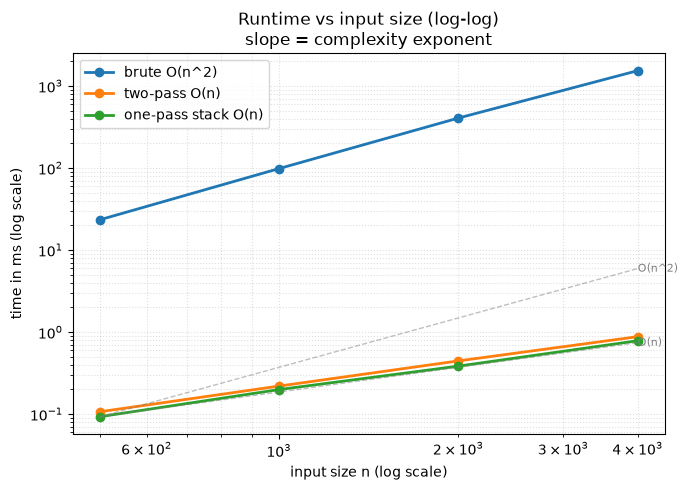

{'brute O(n^2)': [23.284916998818517,
  98.13320892862976,
  405.32166603952646,
  1533.508999971673],
 'two-pass O(n)': [0.10666705202311277,
  0.2194159897044301,
  0.4449170082807541,
  0.8787499973550439],
 'one-pass stack O(n)': [0.09283400140702724,
  0.1990000018849969,
  0.3842920996248722,
  0.7839999161660671]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (list(range(1, n + 1)),)        # rising bars: the stack holds all n, then the sentinel pops all n
solutions = {
    "brute O(n^2)": largest_rectangle_brute,
    "two-pass O(n)": largest_rectangle_two_pass,
    "one-pass stack O(n)": largest_rectangle_stack,
}
sizes = [500, 1000, 2000, 4000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Monotonic Stack](README.md) — an increasing stack of bar indices; when a shorter bar pops a taller one, the current index is the right wall, the new top is the left wall, and the width `i - left - 1` falls out at pop time.
- **"Largest rectangle / span bounded by the smallest element" → next smaller on both sides.** Fix the limiting element, then stretch to the nearest smaller neighbours.
- **Two passes → one pass:** the nearest-smaller-left of a popped bar is exactly what sits below it on the stack, so one pass gives both walls.
- **Sentinel:** a height-0 bar at the end turns the final clean-up into ordinary pops.
- **Signal:** "largest rectangle", "maximum area under a skyline", "span where this element is the minimum", "sum of subarray minimums".
- **Related problems:** Maximal Rectangle (this problem once per matrix row), Daily Temperatures, Sum of Subarray Minimums, Trapping Rain Water (also solvable with a stack).
- **Common pitfalls:**
  1. Width `i - top` instead of `i - left - 1`: the rectangle also extends **left** over the taller bars that were popped before `top`.
  2. Forgetting the sentinel (or a final loop): bars still on the stack never get their area computed — `[1, 2, 3]` would return `0` instead of `4`.
  3. Storing heights instead of indices: the walls are positions.